# Solar Radiation to Temperature Rise: Parameter Tuning

Finds the settings that best predict **how fast air temperature rises (°C per hour)** from **solar radiation**.

Run `weather_station_analysis.ipynb` first. This notebook reads its `output/combined_weather_data.csv` plus the hourly rain file.

**Expected folder layout** (run the notebooks from `senior_design/`):
```
senior_design/
├── summer_data/        1-minute station files (.xlsx)
├── rain_data/          hourly precipitation file (.xlsx)
├── output/             created by weather_station_analysis.ipynb
│   ├── combined_weather_data.csv
│   ├── tuning/         solar_temp_tuning.ipynb results
│   └── sun_warming/    sun_warming_estimate.ipynb results
├── weather_station_analysis.ipynb
├── solar_temp_tuning.ipynb
└── sun_warming_estimate.ipynb
```

**Model**

`rise rate = a × solar(lagged) + b × (block temp − morning temp) + c`

- `a`: warming per W/m² of sun (the number we care about)
- `b`: cooling term. The warmer the air already is compared with the morning, the faster it loses heat, so `b` should come out negative
- The model is also fit without the cooling term for comparison

**Settings that get tuned**

| setting | what it does |
|---|---|
| lag | solar from *lag* minutes earlier is paired with the temperature change (air warms after the ground does) |
| block length | length of each time block the rate is measured over |
| solar threshold | blocks with mean solar below this are dropped (dawn, dusk, heavy overcast) |
| rain buffer | blocks during rain, or within this many hours after it ends, are dropped |
| window | `warming`: only first sun to that day's temperature peak. `daylight`: all sunlit hours (for comparison) |

**Scoring:** days are split into 5 groups. Each group is predicted by a model fit on the other 4, and the score is the R² on those held-out days (**CV R²**). That rewards settings that work on new days, not ones that just fit noise.

## 1. Settings

In [1]:
import os, glob, itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COMBINED_CSV = "output/combined_weather_data.csv"
RAIN_DIR        = "./rain_data"   # folder with the hourly precipitation file
RAIN_FILE       = sorted(glob.glob(os.path.join(RAIN_DIR, "*.xls*")) + glob.glob(os.path.join(RAIN_DIR, "*.csv")))[0]
RAIN_LABEL   = "start"          # same meaning as in the main notebook
OUT_DIR      = "output/tuning"

# search grid (edit to widen or narrow)
LAGS_MIN        = [0, 5, 10, 15, 20, 30, 45, 60]
BLOCKS          = ["15min", "30min", "60min"]
SOLAR_THRESHOLDS = [0, 25, 50, 100]          # W/m2
RAIN_BUFFERS_H  = [0, 1, 2]                  # hours after rain still excluded
WINDOWS         = ["warming"]               # add "daylight" to compare against all sunlit hours
COOLING         = [True, False]

MIN_BLOCKS   = 100     # a setting needs at least this many blocks to be ranked
MIN_COVERAGE = 0.8     # a block needs at least 80% of its minutes present
N_FOLDS      = 5

TIME, TEMP, RH, SOLAR = "time", "temp_C", "rh_pct", "solar_Wm2"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## 2. Load combined data and rain

In [2]:
data = pd.read_csv(COMBINED_CSV, parse_dates=[TIME], index_col=TIME)
step = data.index.to_series().diff().mode().iloc[0]
data = data.asfreq(step)                       # make sure the grid is regular
print(f"Combined data: {data.index.min()} to {data.index.max()}, step {step}, {len(data):,} rows")

# rain: same reader as the main notebook
raw = pd.read_excel(RAIN_FILE, header=None) if RAIN_FILE.endswith(("xlsx", "xls")) else pd.read_csv(RAIN_FILE, header=None)
hdr = next(i for i, v in raw.iloc[:, 0].items() if isinstance(v, str) and v.strip().lower().startswith("date"))
rain = raw.iloc[hdr + 1:, :2].copy()
rain.columns = [TIME, "rain_cm"]
rain[TIME] = pd.to_datetime(rain[TIME], errors="coerce")
rain["rain_cm"] = pd.to_numeric(rain["rain_cm"], errors="coerce")
rain = rain.dropna(subset=[TIME])
offset = pd.Timedelta(0) if RAIN_LABEL == "start" else -pd.Timedelta(hours=1)
wet = rain[rain["rain_cm"] > 0]
rain_spans = pd.DataFrame({"start": wet[TIME] + offset, "end": wet[TIME] + offset + pd.Timedelta(hours=1)})
print(f"Rainy hours: {len(rain_spans)}")

# per-day reference points (from unlagged data)
data["date"] = data.index.normalize()
sun = data[data[SOLAR] > 0]
first_sun = sun.reset_index().groupby("date")[TIME].min()
valid = data.dropna(subset=[TEMP])
peak_time = valid.groupby("date")[TEMP].idxmax()
morning_temp = pd.Series({d: data.loc[t:, TEMP].dropna().iloc[0] for d, t in first_sun.items()
                          if not data.loc[t:, TEMP].dropna().empty})
print(f"Days with sun: {len(first_sun)}")

Combined data: 2026-06-01 00:00:00 to 2026-08-30 23:59:00, step 0 days 00:01:00, 131,040 rows
Rainy hours: 105
Days with sun: 91


## 3. Build the block tables

For each block length, every minute is flagged as rain-affected or not (for each buffer). For each lag, the solar series is shifted and averaged per block. This is done once up front so the grid search itself is fast.

In [3]:
# minute-level rain flags for each buffer
rain_flag = {}
for buf in RAIN_BUFFERS_H:
    flag = pd.Series(False, index=data.index)
    for s, e in zip(rain_spans["start"], rain_spans["end"] + pd.Timedelta(hours=buf)):
        flag.loc[s:e - step] = True
    rain_flag[buf] = flag

def build_blocks(block, lag_min):
    shifted_solar = data[SOLAR].shift(int(pd.Timedelta(minutes=lag_min) / step))
    g = pd.DataFrame({TEMP: data[TEMP], "solar_lag": shifted_solar}).resample(block)
    t = data[TEMP].resample(block)
    first_t = t.apply(lambda x: x.dropna().index[0] if x.notna().any() else pd.NaT)
    last_t = t.apply(lambda x: x.dropna().index[-1] if x.notna().any() else pd.NaT)
    b = pd.DataFrame({
        "solar": g["solar_lag"].mean(),
        "temp_mean": g[TEMP].mean(),
        "t_first": t.first(), "t_last": t.last(),
        "coverage": t.count() / (pd.Timedelta(block) / step),
        "hours": (last_t - first_t).dt.total_seconds() / 3600,
    })
    b["rise"] = (b["t_last"] - b["t_first"]) / b["hours"]
    b["block_end"] = b.index + pd.Timedelta(block)
    b["date"] = b.index.normalize()
    b["first_sun"] = b["date"].map(first_sun)
    b["peak_time"] = b["date"].map(peak_time)
    b["temp_excess"] = b["temp_mean"] - b["date"].map(morning_temp)
    for buf in RAIN_BUFFERS_H:
        b[f"rain_{buf}"] = rain_flag[buf].resample(block).max().reindex(b.index).fillna(False).astype(bool)
    b = b[(b["coverage"] >= MIN_COVERAGE) & (b["hours"] > 0) & b["first_sun"].notna()]
    return b.dropna(subset=["solar", "rise", "temp_excess"])

t0 = time.time()
block_tables = {(blk, lag): build_blocks(blk, lag) for blk in BLOCKS for lag in LAGS_MIN}
print(f"Built {len(block_tables)} block tables in {time.time() - t0:.1f} s")

Built 24 block tables in 30.8 s


## 4. Grid search with day-based cross-validation

In [4]:
def design(b, cooling):
    cols = [b["solar"].values]
    if cooling:
        cols.append(b["temp_excess"].values)
    cols.append(np.ones(len(b)))
    return np.column_stack(cols)

def fit(X, y):
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return coef

def r2(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)

def select(b, thr, buf, window):
    keep = (b["solar"] > thr) & ~b[f"rain_{buf}"]
    keep &= b.index >= b["first_sun"]
    if window == "warming":
        keep &= b["block_end"] <= b["peak_time"]
    return b[keep]

def cross_val(b, cooling):
    days = np.array(sorted(b["date"].unique()))
    fold_of_day = {d: i % N_FOLDS for i, d in enumerate(days)}
    folds = b["date"].map(fold_of_day).values
    X, y = design(b, cooling), b["rise"].values
    pred = np.full(len(y), np.nan)
    for k in range(N_FOLDS):
        test = folds == k
        if test.sum() == 0 or (~test).sum() < X.shape[1] + 2:
            continue
        pred[test] = X[test] @ fit(X[~test], y[~test])
    ok = ~np.isnan(pred)
    return r2(y[ok], pred[ok]), np.sqrt(np.mean((y[ok] - pred[ok]) ** 2))

rows = []
for (blk, lag), b in block_tables.items():
    for thr, buf, window, cooling in itertools.product(SOLAR_THRESHOLDS, RAIN_BUFFERS_H, WINDOWS, COOLING):
        s = select(b, thr, buf, window)
        if len(s) < MIN_BLOCKS or s["date"].nunique() < N_FOLDS:
            continue
        coef = fit(design(s, cooling), s["rise"].values)
        cv_r2, cv_rmse = cross_val(s, cooling)
        rows.append({"block": blk, "lag_min": lag, "solar_threshold": thr, "rain_buffer_h": buf,
                     "window": window, "cooling_term": cooling,
                     "a_solar": coef[0], "b_cooling": coef[1] if cooling else np.nan, "c_intercept": coef[-1],
                     "fit_R2": r2(s["rise"].values, design(s, cooling) @ coef),
                     "cv_R2": cv_r2, "cv_RMSE_C_per_hr": cv_rmse,
                     "n_blocks": len(s), "n_days": s["date"].nunique()})

results = pd.DataFrame(rows).sort_values("cv_R2", ascending=False).reset_index(drop=True)
results.index = results.index + 1
results.index.name = "rank"
print(f"Tested {len(results)} settings")
results.head(15).round(4)

Tested 576 settings


,block,lag_min,solar_threshold,rain_buffer_h,window,cooling_term,a_solar,b_cooling,c_intercept,fit_R2,cv_R2,cv_RMSE_C_per_hr,n_blocks,n_days
rank,,,,,,,,,,,,,,
1,60min,60,25,2,warming,True,-0.0025,0.0983,1.7807,0.2846,0.2789,0.7673,667,90
2,60min,60,50,2,warming,True,-0.0025,0.0936,1.7848,0.2761,0.2705,0.7582,636,90
3,60min,60,25,1,warming,True,-0.0025,0.1004,1.7571,0.2765,0.2700,0.7719,674,90
4,60min,60,0,2,warming,True,-0.0025,0.1057,1.6927,0.2679,0.2636,0.7718,703,90
5,60min,60,25,0,warming,True,-0.0025,0.1048,1.7243,0.2703,0.2625,0.7753,682,90
6,60min,60,50,1,warming,True,-0.0025,0.0958,1.7568,0.2672,0.2605,0.7633,643,90
7,60min,60,0,1,warming,True,-0.0025,0.1074,1.6749,0.2613,0.2566,0.7754,710,90
8,60min,60,50,0,warming,True,-0.0025,0.0999,1.7259,0.2618,0.2540,0.7664,650,90
9,60min,60,0,0,warming,True,-0.0025,0.1113,1.6497,0.2569,0.2516,0.7776,718,90


### Baseline vs best

The baseline is what the main notebook does: 30-minute blocks, no lag, rain left in, all daylight hours, no cooling term. Note that filters change *which* blocks are scored, so part of a higher R² comes from removing hard cases (storms, evenings). That is intended here, since those are the periods where something other than the sun controls temperature.

In [5]:
# baseline: same setup as the main notebook (scored the same way, outside the grid)
bt = block_tables.get(("30min", 0)) if ("30min", 0) in block_tables else build_blocks("30min", 0)
bs = bt[(bt["solar"] > 0) & (bt.index >= bt["first_sun"])]
bcoef = fit(design(bs, False), bs["rise"].values)
b_cv_r2, b_cv_rmse = cross_val(bs, False)
base = pd.DataFrame([{"block": "30min", "lag_min": 0, "solar_threshold": 0, "rain_buffer_h": "not removed",
                      "window": "daylight", "cooling_term": False, "a_solar": bcoef[0], "b_cooling": np.nan,
                      "c_intercept": bcoef[-1], "fit_R2": r2(bs["rise"].values, design(bs, False) @ bcoef),
                      "cv_R2": b_cv_r2, "cv_RMSE_C_per_hr": b_cv_rmse,
                      "n_blocks": len(bs), "n_days": bs["date"].nunique()}])
best = results.iloc[0]
compare = pd.concat([base.assign(setting="baseline (main notebook)"),
                     results.head(1).assign(setting="best tuned")]).set_index("setting")
display(compare.round(4))

print("Best model:")
print(f"  rise (°C/hr) = {best.a_solar:.5f} × solar[{best.lag_min} min earlier]"
      + (f" {best.b_cooling:+.4f} × (temp − morning temp)" if best.cooling_term else "")
      + f" {best.c_intercept:+.3f}")
print(f"  block {best.block}, solar > {best.solar_threshold} W/m², rain + {best.rain_buffer_h} h removed, window = {best.window}")
print(f"  cross-validated R² = {best.cv_R2:.3f}, RMSE = {best.cv_RMSE_C_per_hr:.2f} °C/hr")
print(f"  each extra 100 W/m² of sun adds about {best.a_solar*100:.2f} °C/hr of warming")

,block,lag_min,solar_threshold,rain_buffer_h,window,cooling_term,a_solar,b_cooling,c_intercept,fit_R2,cv_R2,cv_RMSE_C_per_hr,n_blocks,n_days
setting,,,,,,,,,,,,,,
baseline (main notebook),30min,0,0,not removed,daylight,False,0.0018,NaN,-0.3212,0.0823,0.0819,1.7656,2423,91
best tuned,60min,60,25,2,warming,True,-0.0025,0.0983,1.7807,0.2846,0.2789,0.7673,667,90


Best model:
  rise (°C/hr) = -0.00253 × solar[60 min earlier] +0.0983 × (temp − morning temp) +1.781
  block 60min, solar > 25 W/m², rain + 2 h removed, window = warming
  cross-validated R² = 0.279, RMSE = 0.77 °C/hr
  each extra 100 W/m² of sun adds about -0.25 °C/hr of warming


## 5. What each setting does

For each setting, the chart shows the best CV R² reached when that setting is held at each value and everything else is free. A flat line means the setting barely matters.

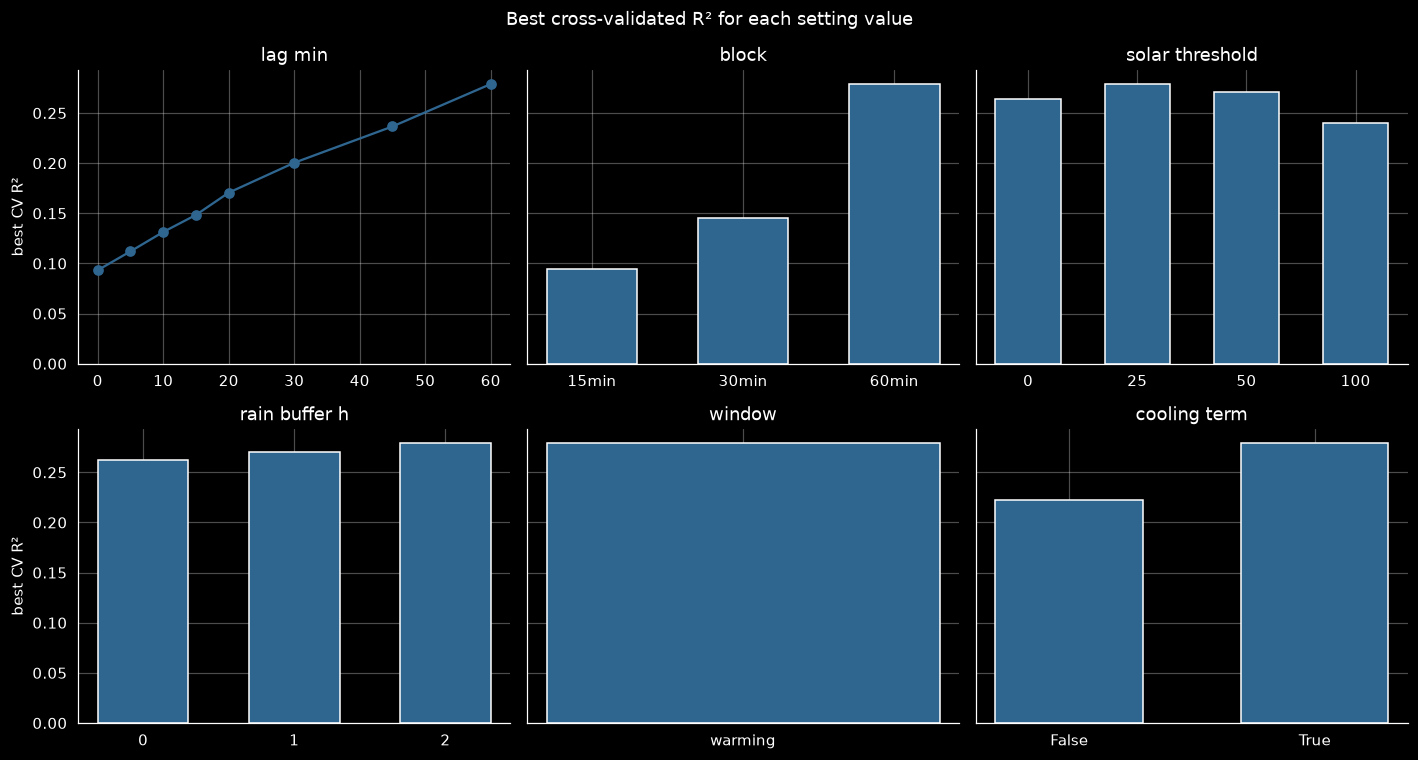

In [6]:
params = ["lag_min", "block", "solar_threshold", "rain_buffer_h", "window", "cooling_term"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, p in zip(axes.flat, params):
    best_by = results.groupby(p)["cv_R2"].max()
    if p == "block":
        best_by = best_by.reindex(BLOCKS)
    x = [str(v) for v in best_by.index]
    if p == "lag_min":
        ax.plot(best_by.index, best_by.values, marker="o", color="#2f6690")
    else:
        ax.bar(x, best_by.values, color="#2f6690", width=0.6)
    ax.set_title(p.replace("_", " "))
axes[0, 0].set_ylabel("best CV R²"); axes[1, 0].set_ylabel("best CV R²")
fig.suptitle("Best cross-validated R² for each setting value")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "setting_effects.png"), dpi=200, bbox_inches="tight")
plt.show()

## 6. Best model plots

Left: observed vs predicted rise rate (perfect predictions fall on the dashed line). Right: the sun's effect alone. When the cooling term is used, its part is removed from each point (`rise − b × temp excess`) so the solar relationship can be seen on its own.

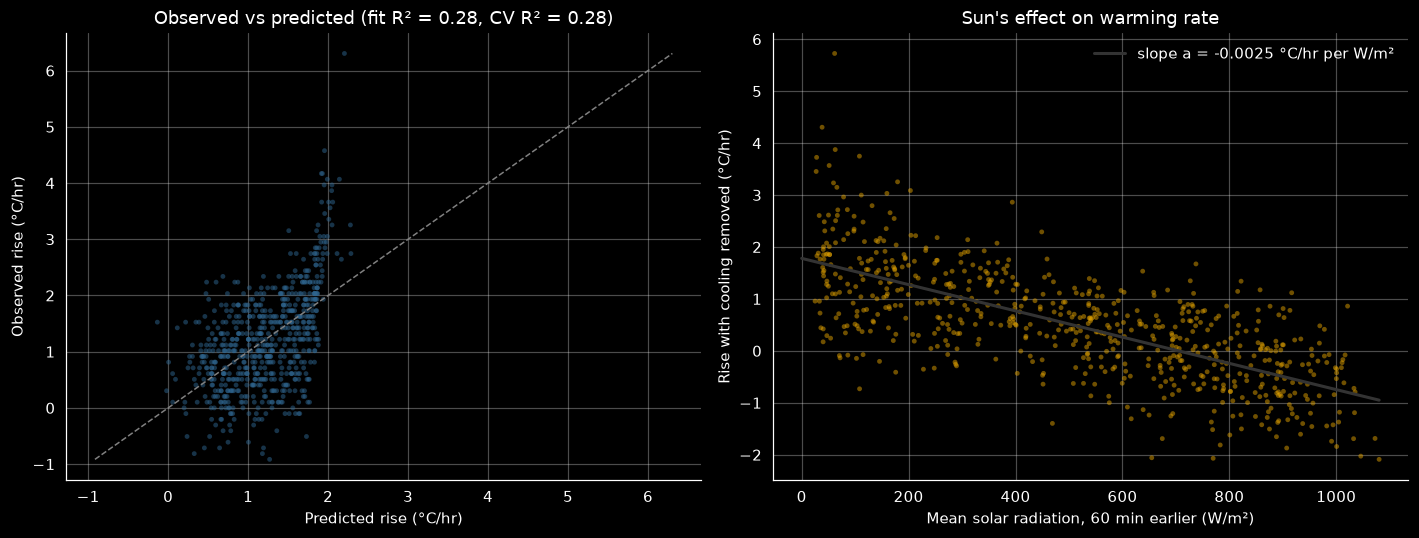

In [7]:
bb = select(block_tables[(best.block, best.lag_min)], best.solar_threshold, best.rain_buffer_h, best.window)
coef = fit(design(bb, best.cooling_term), bb["rise"].values)
pred = design(bb, best.cooling_term) @ coef

def predict_rise(solar_Wm2, temp_excess_C=0.0):
    # predicted warming rate (°C/hr) from lagged solar (W/m2) and temp above the morning value (°C)
    out = best.a_solar * np.asarray(solar_Wm2) + best.c_intercept
    if best.cooling_term:
        out = out + best.b_cooling * np.asarray(temp_excess_C)
    return out

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(pred, bb["rise"], s=10, alpha=0.5, color="#2f6690", edgecolor="none")
lim = [min(pred.min(), bb["rise"].min()), max(pred.max(), bb["rise"].max())]
ax1.plot(lim, lim, "--", color="grey", lw=1)
ax1.set_xlabel("Predicted rise (°C/hr)"); ax1.set_ylabel("Observed rise (°C/hr)")
ax1.set_title(f"Observed vs predicted (fit R² = {r2(bb['rise'].values, pred):.2f}, CV R² = {best.cv_R2:.2f})")

solar_part = bb["rise"] - (coef[1] * bb["temp_excess"] if best.cooling_term else 0)
ax2.scatter(bb["solar"], solar_part, s=10, alpha=0.5, color="#e0a100", edgecolor="none")
xs = np.linspace(0, bb["solar"].max(), 100)
ax2.plot(xs, coef[0] * xs + coef[-1], color="#333333", lw=2, label=f"slope a = {coef[0]:.4f} °C/hr per W/m²")
ax2.set_xlabel(f"Mean solar radiation, {best.lag_min} min earlier (W/m²)")
ax2.set_ylabel("Rise with cooling removed (°C/hr)" if best.cooling_term else "Rise (°C/hr)")
ax2.set_title("Sun's effect on warming rate"); ax2.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "best_model.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7. Save results

In [8]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

xlsx = os.path.join(OUT_DIR, "tuning_results.xlsx")
sheets = {
    "Best vs baseline": ("Best tuned setting compared with the main notebook's setup. cv_R2 is scored on held-out days.", compare.reset_index()),
    "All settings": ("Every setting tested, ranked by cross-validated R2. a_solar = warming per W/m2, b_cooling = cooling term.", results.reset_index()),
    "Best model blocks": ("The blocks used by the best model: lagged solar, temperature above morning, observed and predicted rise.",
                          bb[["date", "solar", "temp_excess", "rise"]].assign(predicted=pred).reset_index()),
}
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    for name, (desc, t) in sheets.items():
        t = t.copy()
        for c in t.columns:
            if t[c].dtype.kind == "f":
                t[c] = t[c].round(6)
        t.to_excel(xw, sheet_name=name, index=False, startrow=3)
        ws = xw.sheets[name]
        ws["A1"] = name; ws["A1"].font = Font(name="Arial", size=12, bold=True)
        ws["A2"] = desc; ws["A2"].font = Font(name="Arial", size=10, italic=True, color="555555")
        for row in ws.iter_rows(min_row=4):
            for cell in row:
                cell.font = Font(name="Arial", size=10, bold=cell.row == 4)
                if cell.row == 4:
                    cell.fill = PatternFill("solid", fgColor="DCE6F1")
                elif hasattr(cell.value, "hour"):
                    cell.number_format = "yyyy-mm-dd hh:mm"
        for i, col in enumerate(t.columns, 1):
            ws.column_dimensions[get_column_letter(i)].width = min(max(len(str(col)) + 2, 12), 30)
        ws.freeze_panes = "A5"

print("Saved to", os.path.abspath(OUT_DIR))
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

Saved to /home/biceplover/IRES_AUSTRIA/senior_design/output/tuning
   best_model.png
   setting_effects.png
   tuning_results.xlsx
